In [5]:
import pandas as pd
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print(os.getcwd())


/home/sarah/Documents/Project_Ugent


## Create fasta file

NBsTem_Q and NBsTem_em require a fasta file as input. 

In [2]:
fap_nanobodies = pd.read_csv("all_designs_metrics.csv")
fap_nanobodies_top100 = fap_nanobodies.head(100)

IL7RA_nanobodies = pd.read_csv("IL-7RA binders_summary.csv")
# Only select nanobody designs
IL7RA_nanobodies = IL7RA_nanobodies[IL7RA_nanobodies["name"].str.contains("nano")]

with open("fap_nanobodies.fasta", "w") as fasta_file:
    for index, row in fap_nanobodies.iterrows():
        fasta_file.write(f">id:{row['id']}_final_rank:{row['final_rank']}\n{row['designed_chain_sequence']}\n")

with open("fap_nanobodies_top_100.fasta", "w") as fasta_file:
    for index, row in fap_nanobodies_top100.iterrows():
        fasta_file.write(f">id:{row['id']}_final_rank:{row['final_rank']}\n{row['designed_chain_sequence']}\n")

with open("IL7RA_nanobodies_top_15.fasta", "w") as fasta_file:
    for index, row in IL7RA_nanobodies.iterrows():
        fasta_file.write(f">id:{row['name']}_binding:{row['binding']}\n{row['sequence']}\n")

## Load results

Load the results optained from the NBsTem and NBsTem_Q model

In [2]:
Tm_results_fap = pd.read_csv("/home/sarah/Documents/Project_Ugent/NBsTem/NBsTem_local/NBsTem_FAP.csv")
Tm_results_IL7RA = pd.read_csv("/home/sarah/Documents/Project_Ugent/NBsTem/NBsTem_local/NBsTem_IL7RA_top15.csv")
Tm_results_confirmed_low_homology_binders = pd.read_csv("/home/sarah/Documents/Project_Ugent/NBsTem/NBsTem_local/Tm_confirmed_low_homology_binders.fasta")

In [6]:
Tm_results_IL7RA["binding"] = (Tm_results_IL7RA["ID"].str.extract(r"(True|False)")[0].map({"True": True, "False": False}))
Tm_results_confirmed_low_homology_binders["binding"] = True

In [11]:
Tm_results_combined = pd.concat([Tm_results_IL7RA,Tm_results_confirmed_low_homology_binders],ignore_index=True)
Tm_results_combined

,Unnamed: 0,ID,Tm,Tm_Uncertainty,Qclass,Q_Uncertainty,Specie,Sequence,binding
0,1,id:il7ranano_42829_binding:False,71.65,2.85,2,-1.000000e-08,Camel,EVQLVESGGGLVQPGGSLRLSCAASGDVKSVLAMAWYRQAPGKGRE...,False
1,2,id:il7ranano_19230_binding:False,70.82,1.87,2,-1.000000e-08,Camel,EVQLVESGGGLVQPGGSLRLSCAASGDILDILAMAWYRQAPGKGRE...,False
2,3,id:il7ranano_25867_binding:False,75.23,2.15,2,-1.000000e-08,Camel,EVQLVESGGGLVQPGGSLRLSCAASGDIDEILSMAWYRQAPGKGRE...,False
3,4,id:il7ranano_29930_binding:False,69.91,4.07,2,-1.000000e-08,Camel,EVQLVESGGGLVQPGGSLRLSCAASGDVKSILSMAWYRQAPGKGRE...,False
4,5,id:il7ranano_02781_binding:False,68.14,2.14,2,9.710000e-01,Camel,EVQLVESGGGLVQPGGSLRLSCAASGDVKSIYNMAWYRQAPGKGRE...,False
5,6,id:il7ranano_08947_binding:True,69.99,3.09,2,7.220000e-01,Camel,EVQLVESGGGLVQPGGSLRLSCAASGSILSILSMAWYRQAPGKGRE...,True
6,7,id:il7ranano_15077_binding:False,69.06,1.91,2,-1.000000e-08,Human,EVQLVESGGGLVQPGGSLRLSCAASGFSETILSMAWYRQAPGKGRE...,False
7,8,id:il7ranano_19229_binding:True,67.42,2.15,2,-1.000000e-08,Camel,EVQLVESGGGLVQPGGSLRLSCAASGFSGTIYAMAWYRQAPGKGRE...,True
8,9,id:il7ranano_51172_binding:False,75.92,1.63,2,-1.000000e-08,Camel,EVQLVESGGGLVQPGGSLRLSCAASGDVASILSMAWYRQAPGKGRE...,False
9,10,id:il7ranano_33394_binding:False,70.08,3.28,2,7.220000e-01,Camel,EVQLVESGGGLVQPGGSLRLSCAASGDVKSVLAMAWYRQAPGKGRE...,False


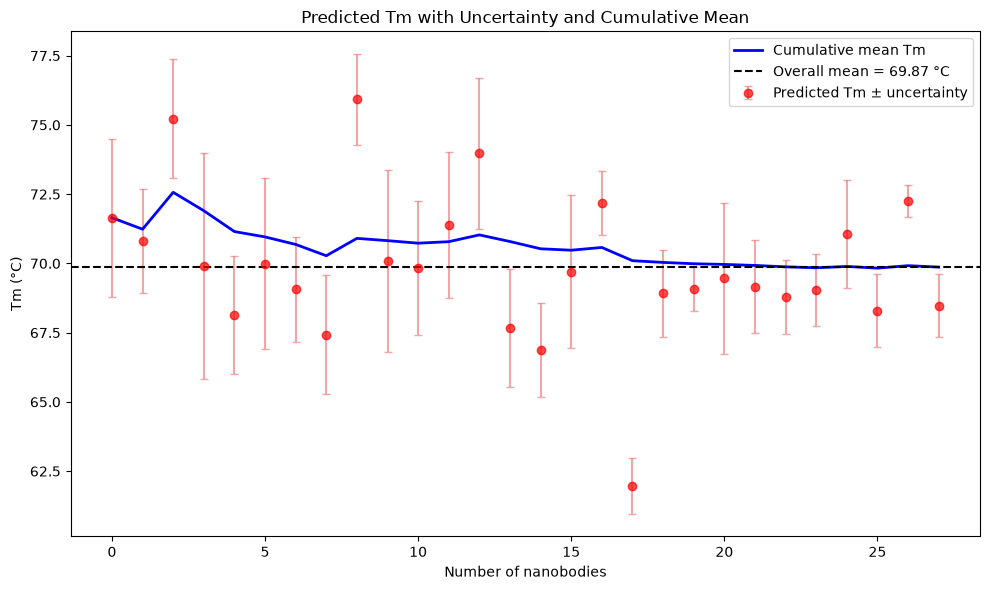

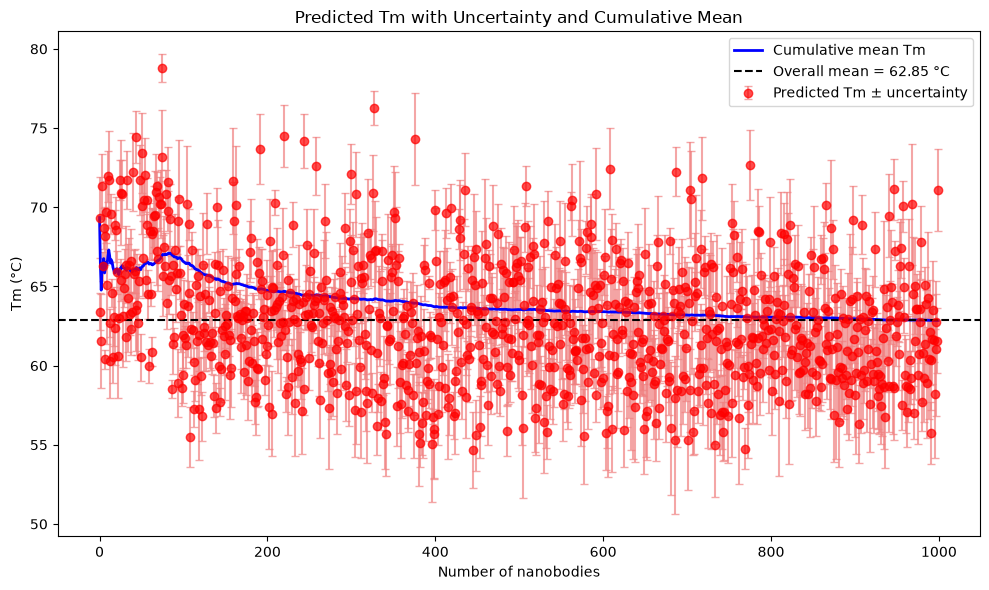

In [16]:
def plot_tm_with_uncertainty(results_Tm):
    # Extract data
    x = np.arange(len(results_Tm))
    tm = results_Tm['Tm']
    uncertainty = results_Tm['Tm_Uncertainty']

    # Calculate means
    cumulative_mean = tm.expanding().mean()
    overall_mean = tm.mean()

    fig, ax = plt.subplots(figsize=(10, 6))

    # Individual Tm predictions with error bars
    ax.errorbar(
        x, tm,
        yerr=uncertainty,
        fmt='o',
        color='red',
        ecolor='lightcoral',
        capsize=3,
        alpha=0.7,
        label='Predicted Tm ± uncertainty'
    )

    # Cumulative mean
    ax.plot(
        x, cumulative_mean,
        color='blue',
        linewidth=2,
        label='Cumulative mean Tm'
    )

    # Overall mean
    ax.axhline(
        overall_mean,
        color='black',
        linestyle='--',
        label=f'Overall mean = {overall_mean:.2f} °C'
    )

    ax.set_xlabel('Number of nanobodies')
    ax.set_ylabel('Tm (°C)')
    ax.set_title('Predicted Tm with Uncertainty and Cumulative Mean')

    ax.legend()
    plt.tight_layout()
    plt.show()

plot_tm_with_uncertainty(Tm_results_combined)
plot_tm_with_uncertainty(Tm_results_fap)

NameError: name 'results_Tm' is not defined

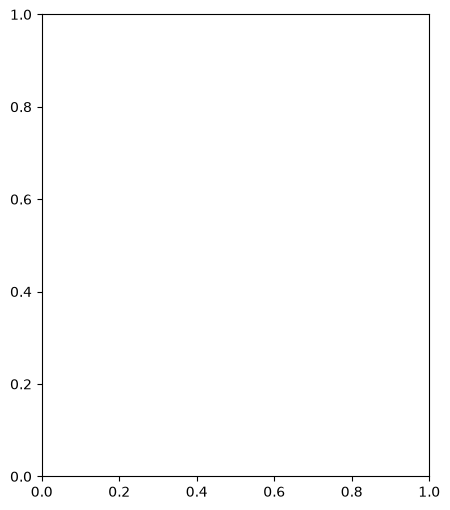

In [ ]:

fig, ax = plt.subplots(figsize=(5, 6))

# Boxplot
sns.boxplot(
    y=results_Tm['Tm'],
    ax=ax,
    color='lightblue',
    width=0.4,
    showfliers=False
)

# Individuele punten
sns.stripplot(
    y=results_Tm['Tm'],
    ax=ax,
    color='red',
    size=4,
    alpha=0.5,
    jitter=0.15
)

# Gemiddelde
mean_tm = results_Tm['Tm'].mean()

ax.axhline(
    mean_tm,
    color='black',
    linestyle='--',
    label=f'Mean = {mean_tm:.2f} °C'
)

ax.set_ylabel('Predicted Tm (°C)')
ax.set_title('Distribution of Predicted Nanobody Tm')
ax.legend()

plt.tight_layout()
plt.show()

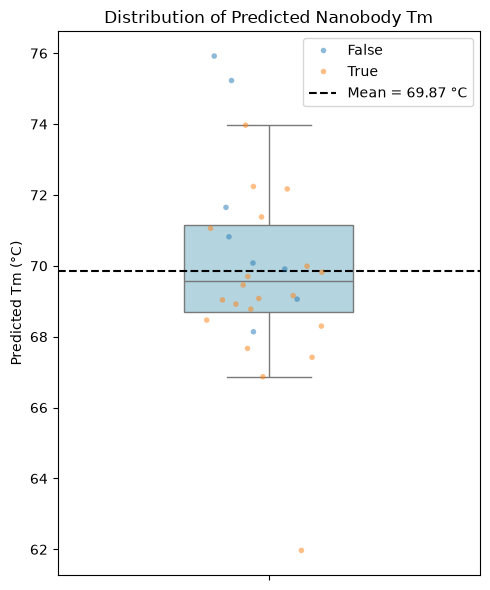

In [42]:
fig, ax = plt.subplots(figsize=(5, 6))

# Boxplot
sns.boxplot(
    y=Tm_results_combined['Tm'],
    ax=ax,
    color='lightblue',
    width=0.4,
    showfliers=False
)

# Individuele punten
sns.stripplot(
    y=Tm_results_combined['Tm'],
    ax=ax,
    hue=Tm_results_combined['binding'],
    size=4,
    alpha=0.5,
    jitter=0.15
)

# Gemiddelde
mean_tm = Tm_results_combined['Tm'].mean()

ax.axhline(
    mean_tm,
    color='black',
    linestyle='--',
    label=f'Mean = {mean_tm:.2f} °C'
)

ax.set_ylabel('Predicted Tm (°C)')
ax.set_title('Distribution of Predicted Nanobody Tm')
ax.legend()

plt.tight_layout()
plt.show()

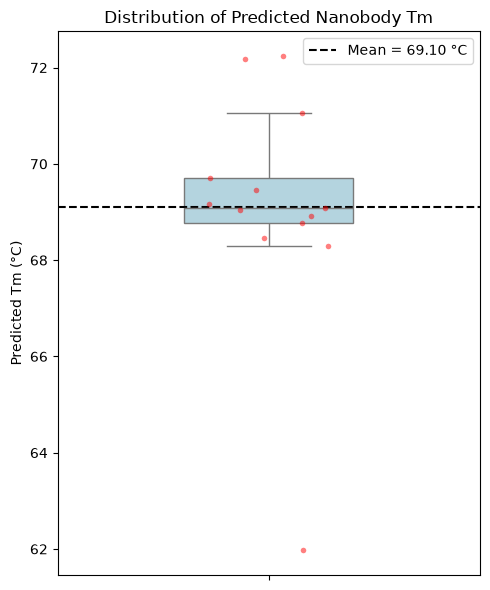

In [36]:
fig, ax = plt.subplots(figsize=(5, 6))

# Boxplot
sns.boxplot(
    y=Tm_results_confirmed_low_homology_binders['Tm'],
    ax=ax,
    color='lightblue',
    width=0.4,
    showfliers=False
)

# Individuele punten
sns.stripplot(
    y=Tm_results_confirmed_low_homology_binders['Tm'],
    ax=ax,
    #hue=Tm_results_confirmed_low_homology_binders['binding'],
    size=4,
    alpha=0.5,
    jitter=0.15,
    color='red'
)

# Gemiddelde
mean_tm = Tm_results_confirmed_low_homology_binders['Tm'].mean()

ax.axhline(
    mean_tm,
    color='black',
    linestyle='--',
    label=f'Mean = {mean_tm:.2f} °C'
)

ax.set_ylabel('Predicted Tm (°C)')
ax.set_title('Distribution of Predicted Nanobody Tm')
ax.legend()

plt.tight_layout()
plt.show()